# Import required Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


# Read Dataset

In [2]:
df=pd.read_csv(r"D:\New folder\diabetes.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Checking Null Value

In [4]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [5]:
df['Outcome'].value_counts()

0    500
1    268
Name: Outcome, dtype: int64

Separate label and Data

In [6]:
data=df.iloc[:,:-1]
label=df.iloc[:,-1]

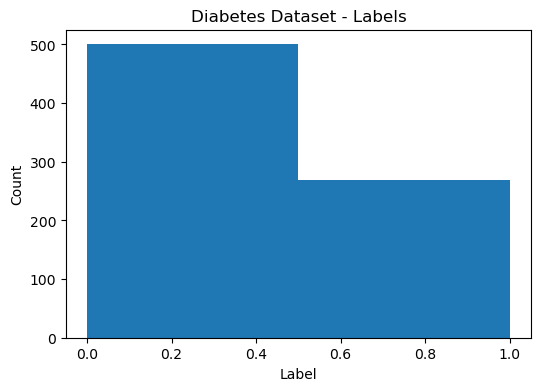

In [7]:
# Visualize the labels
plt.figure(figsize=(6, 4))
plt.hist(label, bins=2)
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Diabetes Dataset - Labels')
plt.show()

In [8]:
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


Standarize the Data 

In [9]:
scale=StandardScaler()

In [10]:
scale.fit(data)

StandardScaler()

In [11]:
x=scale.transform(data)
y=df.iloc[:,-1]

Splitting Data For training And Validation

In [12]:
xtrain,xtest,ytrain,ytest=train_test_split(data,label,test_size=0.2, random_state=2)

In [13]:
xtrain

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
602,1,124,74,36,0,27.8,0.100,30
429,1,95,82,25,180,35.0,0.233,43
623,0,94,70,27,115,43.5,0.347,21
209,7,184,84,33,0,35.5,0.355,41
589,0,73,0,0,0,21.1,0.342,25
...,...,...,...,...,...,...,...,...
534,1,77,56,30,56,33.3,1.251,24
584,8,124,76,24,600,28.7,0.687,52
493,4,125,70,18,122,28.9,1.144,45
527,3,116,74,15,105,26.3,0.107,24


In [14]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

# Create a logistic regression model

In [15]:
model=LogisticRegression()

# Fit the logistic regression model to the training data

In [16]:
model.fit(xtrain,ytrain)

C:\Users\Muhammad Haroon\anaconda3\New folder\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

# Make Prediction on unseen data

In [17]:
prediction=model.predict(xtest)

# Confusion Matrix

In [18]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(ytest, prediction)
print(cm)

[[96 13]
 [23 22]]


# checking the result On Unseen Data

In [19]:
input=(3,126,88,41,235,39.3,0.704,27)

In [20]:
input_array=np.asarray(input)

In [21]:
input_reshape=input_array.reshape(1,-1)

In [22]:
data=scale.transform(input_reshape)

C:\Users\Muhammad Haroon\anaconda3\New folder\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [23]:
print(data)

[[-0.25095213  0.1597866   0.97680475  1.28363829  1.34758997  0.92745247
   0.70104112 -0.53102292]]


In [24]:
prediction=model.predict(data)
print(prediction)
if(prediction[0]==1):
    print("This patient have Diabetics",prediction)
else:
    print("no diabetics",prediction)

[0]
no diabetics [0]


C:\Users\Muhammad Haroon\anaconda3\New folder\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
